In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
os.chdir('/content/drive/MyDrive/PIML Project')
print("Current directory:", os.getcwd())

Current directory: /content/drive/MyDrive/PIML Project


Saved hill_dataset.npz successfully! Shape: (500, 200)


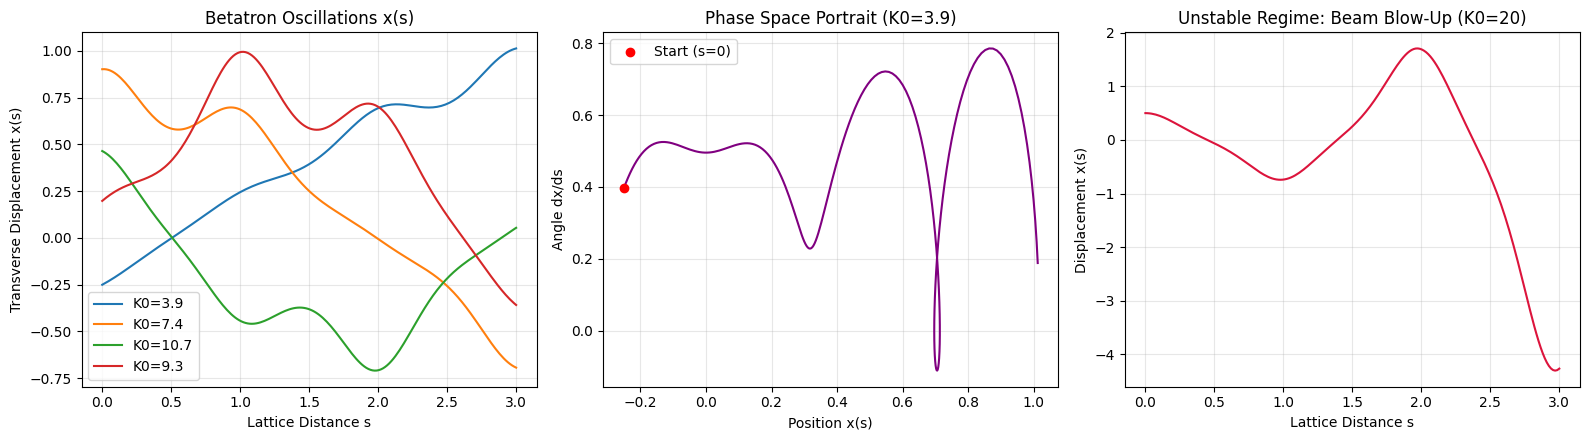

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

def hills_ode(s, y, K0):
    x, x_prime = y
    K_s = K0 * np.cos(2 * np.pi * s)
    d2x_ds2 = -K_s * x
    return [x_prime, d2x_ds2]

np.random.seed(42)
num_samples = 500
num_points = 200
s_eval = np.linspace(0, 3, num_points)


x0_samples = np.random.uniform(-1.0, 1.0, num_samples)
xp0_samples = np.random.uniform(-1.0, 1.0, num_samples)
K0_samples = np.random.uniform(2.0, 12.0, num_samples)

X_trajectories = np.zeros((num_samples, num_points))
Xp_trajectories = np.zeros((num_samples, num_points))

for i in range(num_samples):
    sol = solve_ivp(
        hills_ode,
        t_span=(0, 3),
        y0=[x0_samples[i], xp0_samples[i]],
        args=(K0_samples[i],),
        t_eval=s_eval,
        method='DOP853',
        rtol=1e-10,
        atol=1e-12
    )
    X_trajectories[i] = sol.y[0]
    Xp_trajectories[i] = sol.y[1]


np.savez(
    'hill_dataset.npz',
    s=s_eval,
    x0=x0_samples,
    xp0=xp0_samples,
    K0=K0_samples,
    X=X_trajectories,
    Xp=Xp_trajectories
)
print("Saved hill_dataset.npz successfully! Shape:", X_trajectories.shape)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Plot A: Stable Betatron Oscillations
for idx in range(4):
    axes[0].plot(s_eval, X_trajectories[idx], label=f"K0={K0_samples[idx]:.1f}")
axes[0].set_title("Betatron Oscillations x(s)")
axes[0].set_xlabel("Lattice Distance s")
axes[0].set_ylabel("Transverse Displacement x(s)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot B: Phase Space (x vs dx/ds) for one trajectory
axes[1].plot(X_trajectories[0], Xp_trajectories[0], color='purple')
axes[1].scatter(X_trajectories[0, 0], Xp_trajectories[0, 0], color='red', zorder=5, label='Start (s=0)')
axes[1].set_title(f"Phase Space Portrait (K0={K0_samples[0]:.1f})")
axes[1].set_xlabel("Position x(s)")
axes[1].set_ylabel("Angle dx/ds")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Plot C: Beam Blow-Up above Stability Limit (K0 = 20)
sol_unstable = solve_ivp(hills_ode, (0, 3), [0.5, 0.0], args=(20.0,), t_eval=s_eval, method='DOP853')
axes[2].plot(s_eval, sol_unstable.y[0], color='crimson')
axes[2].set_title("Unstable Regime: Beam Blow-Up (K0=20)")
axes[2].set_xlabel("Lattice Distance s")
axes[2].set_ylabel("Displacement x(s)")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Training Improved PINN on cpu for K0 = 10.73, x0 = 0.46, x'0 = -0.38
[Adam] Epoch 500/1500 | Weighted Residual Loss: 2.78e-02
[Adam] Epoch 1000/1500 | Weighted Residual Loss: 3.39e-03
[Adam] Epoch 1500/1500 | Weighted Residual Loss: 4.63e-04
[L-BFGS] Final Loss: 2.72e-06

Total Training Time: 21.82s | Relative L2 Error: 0.0466%


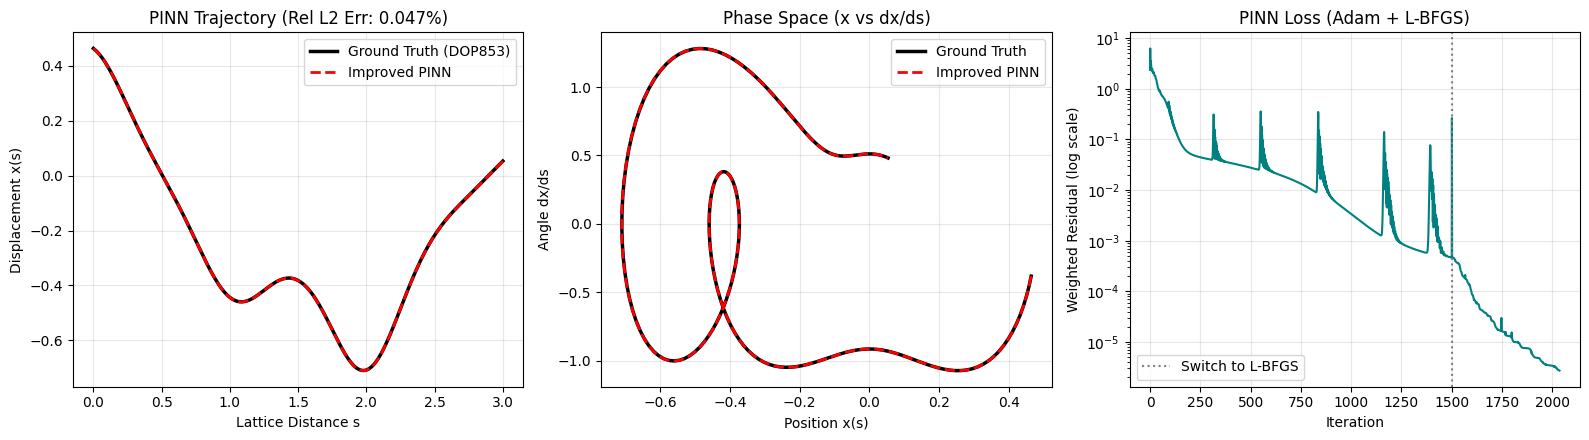

In [ ]:
import time
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

data = np.load('hill_dataset.npz')
s_np = data['s']
idx = 2

x0_val = float(data['x0'][idx])
xp0_val = float(data['xp0'][idx])
K0_val = float(data['K0'][idx])
x_true = data['X'][idx]
xp_true = data['Xp'][idx]

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Training Improved PINN on {device} for K0 = {K0_val:.2f}, x0 = {x0_val:.2f}, x'0 = {xp0_val:.2f}")

# Improved PINN with Bounded Ansatz & Periodic Feature Encoding
class ImprovedTrajectoryPINN(nn.Module):
    def __init__(self, hidden_dim=64):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(3, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, 1)
        )

    def forward(self, s):
        features = torch.cat([
            s / 3.0,
            torch.cos(2.0 * np.pi * s),
            torch.sin(2.0 * np.pi * s)
        ], dim=1)

        gate = (1.0 - torch.exp(-s)) ** 2
        return x0_val + xp0_val * s + gate * self.net(features)

torch.manual_seed(42)
pinn = ImprovedTrajectoryPINN(hidden_dim=64).to(device)
s_colloc = torch.linspace(0, 3, 400, device=device).view(-1, 1)

def compute_physics_loss():
    s_req = s_colloc.clone().detach().requires_grad_(True)
    x_pred = pinn(s_req)
    dx_ds = torch.autograd.grad(x_pred, s_req, torch.ones_like(x_pred), create_graph=True)[0]
    d2x_ds2 = torch.autograd.grad(dx_ds, s_req, torch.ones_like(dx_ds), create_graph=True)[0]

    K_s = K0_val * torch.cos(2.0 * np.pi * s_req)
    residual = d2x_ds2 + K_s * x_pred

    # Mild causal weighting to prevent early collapse to x=0 at large s
    causal_weight = torch.exp(-0.5 * s_req.detach())
    return torch.mean(causal_weight * (residual ** 2))

#  Adam  (1500 epochs)
start_time = time.time()
loss_history = []
optimizer_adam = torch.optim.Adam(pinn.parameters(), lr=3e-3)

for epoch in range(1500):
    optimizer_adam.zero_grad()
    loss = compute_physics_loss()
    loss.backward()
    optimizer_adam.step()
    loss_history.append(loss.item())
    if (epoch + 1) % 500 == 0:
        print(f"[Adam] Epoch {epoch+1}/1500 | Weighted Residual Loss: {loss.item():.2e}")

# 4.L-BFGS Second-Order Polish
optimizer_lbfgs = torch.optim.LBFGS(
    pinn.parameters(),
    lr=1.0,
    max_iter=500,
    history_size=50,
    line_search_fn="strong_wolfe"
)

def closure():
    optimizer_lbfgs.zero_grad()
    loss = compute_physics_loss()
    loss.backward()
    loss_history.append(loss.item())
    return loss

optimizer_lbfgs.step(closure)
train_time = time.time() - start_time
print(f"[L-BFGS] Final Loss: {loss_history[-1]:.2e}")

s_test = torch.tensor(s_np, dtype=torch.float32, device=device).view(-1, 1).requires_grad_(True)
x_pinn = pinn(s_test)
xp_pinn = torch.autograd.grad(x_pinn, s_test, torch.ones_like(x_pinn))[0]

x_pinn_np = x_pinn.detach().cpu().numpy().flatten()
xp_pinn_np = xp_pinn.detach().cpu().numpy().flatten()

rel_l2_error = np.linalg.norm(x_pinn_np - x_true) / np.linalg.norm(x_true)
print(f"\nTotal Training Time: {train_time:.2f}s | Relative L2 Error: {rel_l2_error*100:.4f}%")

torch.save(pinn.state_dict(), 'pinn_single_traj.pt')

# Plot
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].plot(s_np, x_true, 'k-', lw=2.5, label='Ground Truth (DOP853)')
axes[0].plot(s_np, x_pinn_np, 'r--', lw=2, label='Improved PINN')
axes[0].set_title(f"PINN Trajectory (Rel L2 Err: {rel_l2_error*100:.3f}%)")
axes[0].set_xlabel("Lattice Distance s")
axes[0].set_ylabel("Displacement x(s)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(x_true, xp_true, 'k-', lw=2.5, label='Ground Truth')
axes[1].plot(x_pinn_np, xp_pinn_np, 'r--', lw=2, label='Improved PINN')
axes[1].set_title("Phase Space (x vs dx/ds)")
axes[1].set_xlabel("Position x(s)")
axes[1].set_ylabel("Angle dx/ds")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

axes[2].semilogy(loss_history, color='teal')
axes[2].axvline(1500, color='gray', linestyle=':', label='Switch to L-BFGS')
axes[2].set_title("PINN Loss (Adam + L-BFGS)")
axes[2].set_xlabel("Iteration")
axes[2].set_ylabel("Weighted Residual (log scale)")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Training Upgraded PI-DeepONet on cpu...
[Adam] Epoch 500/1500 | Data Loss: 2.89e-02 | Physics Loss: 1.79e+00
[Adam] Epoch 1000/1500 | Data Loss: 1.43e-02 | Physics Loss: 1.14e+00
[Adam] Epoch 1500/1500 | Data Loss: 1.22e-02 | Physics Loss: 5.24e-01
[L-BFGS] Final Data Loss: 2.01e-03 | Final Physics Loss: 8.00e-02

Operator Training Time: 363.74s
Inference Time for 100 Unseen Trajectories: 129.67 ms (1.297 ms/traj)
Mean Relative L2 Error across 100 Unseen Tests: 6.110% (Median: 5.561%)


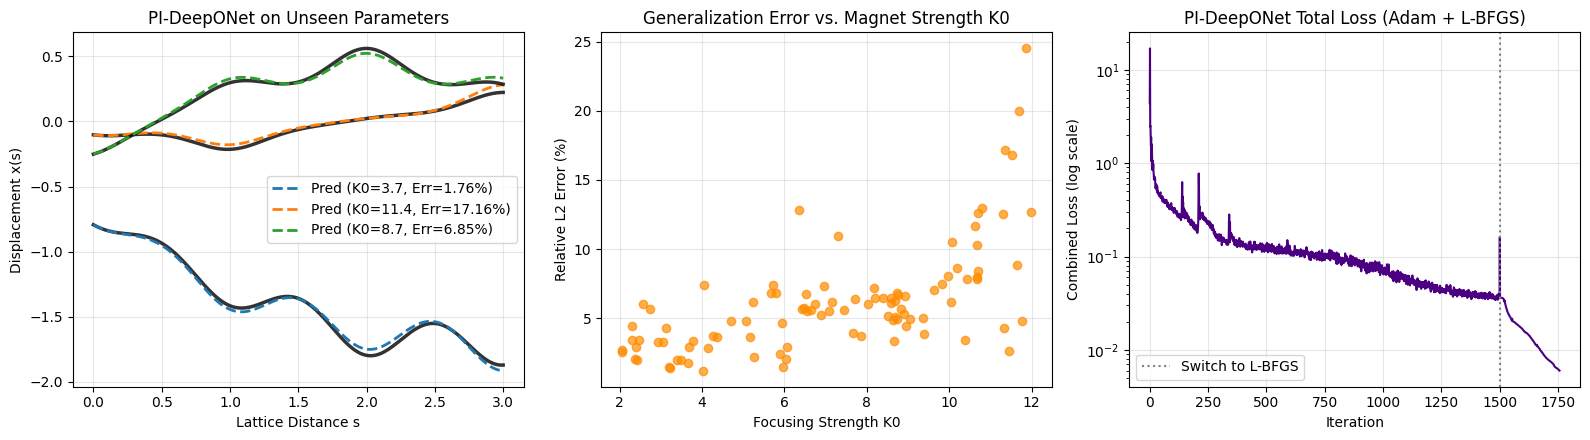

In [ ]:
import time
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt


data = np.load('hill_dataset.npz')
s_np = data['s']
x0_all, xp0_all, K0_all = data['x0'], data['xp0'], data['K0']
X_all, Xp_all = data['X'], data['Xp']

x0_train, xp0_train, K0_train, X_train = x0_all[:400], xp0_all[:400], K0_all[:400], X_all[:400]
x0_test, xp0_test, K0_test, X_test = x0_all[400:], xp0_all[400:], K0_all[400:], X_all[400:]

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Training Upgraded PI-DeepONet on {device}...")


class PIDeepONet(nn.Module):
    def __init__(self, branch_dim=100, hidden_dim=100):
        super().__init__()
        self.branch = nn.Sequential(
            nn.Linear(3, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, branch_dim)
        )

        self.trunk = nn.Sequential(
            nn.Linear(5, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, branch_dim)
        )
        self.bias = nn.Parameter(torch.zeros(1))

    def forward(self, x0, xp0, K0, s):
        K0_norm = (K0 - 7.0) / 5.0
        branch_in = torch.cat([x0, xp0, K0_norm], dim=1)
        trunk_in = torch.cat([
            s / 3.0,
            torch.cos(2.0 * np.pi * s),
            torch.sin(2.0 * np.pi * s),
            torch.cos(4.0 * np.pi * s),
            torch.sin(4.0 * np.pi * s)
        ], dim=1)

        b_out = self.branch(branch_in)
        t_out = self.trunk(trunk_in)
        operator_out = torch.sum(b_out * t_out, dim=1, keepdim=True) + self.bias

        gate = (1.0 - torch.exp(-s)) ** 2
        return x0 + xp0 * s + gate * operator_out

torch.manual_seed(42)
deeponet = PIDeepONet(branch_dim=100, hidden_dim=100).to(device)

s_sub_idx = np.linspace(0, len(s_np) - 1, 50, dtype=int)
s_sub = torch.tensor(s_np[s_sub_idx], dtype=torch.float32, device=device).view(-1, 1)

x0_grid = torch.tensor(x0_train, dtype=torch.float32, device=device).view(-1, 1).repeat_interleave(50, dim=0)
xp0_grid = torch.tensor(xp0_train, dtype=torch.float32, device=device).view(-1, 1).repeat_interleave(50, dim=0)
K0_grid = torch.tensor(K0_train, dtype=torch.float32, device=device).view(-1, 1).repeat_interleave(50, dim=0)
s_grid = s_sub.repeat(400, 1)
x_target_grid = torch.tensor(X_train[:, s_sub_idx], dtype=torch.float32, device=device).reshape(-1, 1)

def compute_total_loss(batch_idx=None):
    if batch_idx is None:
        x0_b, xp0_b, K0_b, s_b, x_targ = x0_grid, xp0_grid, K0_grid, s_grid, x_target_grid
    else:
        x0_b = x0_grid[batch_idx]
        xp0_b = xp0_grid[batch_idx]
        K0_b = K0_grid[batch_idx]
        s_b = s_grid[batch_idx]
        x_targ = x_target_grid[batch_idx]

    s_req = s_b.clone().detach().requires_grad_(True)
    x_pred = deeponet(x0_b, xp0_b, K0_b, s_req)


    dx_ds = torch.autograd.grad(x_pred, s_req, torch.ones_like(x_pred), create_graph=True)[0]
    d2x_ds2 = torch.autograd.grad(dx_ds, s_req, torch.ones_like(dx_ds), create_graph=True)[0]
    residual = d2x_ds2 + (K0_b * torch.cos(2.0 * np.pi * s_req)) * x_pred
    loss_phys = torch.mean(residual ** 2)

    loss_data = torch.mean((x_pred - x_targ) ** 2)
    return loss_data + 0.05 * loss_phys, loss_data.item(), loss_phys.item()

# Mini-Batch Adam (1500 epochs)
start_time = time.time()
loss_history = []
optimizer_adam = torch.optim.Adam(deeponet.parameters(), lr=2e-3)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_adam, T_max=1500, eta_min=1e-4)
total_pts = len(x0_grid)

for epoch in range(1500):
    optimizer_adam.zero_grad()
    b_idx = torch.randint(0, total_pts, (2048,), device=device)
    loss, l_d, l_p = compute_total_loss(b_idx)
    loss.backward()
    optimizer_adam.step()
    scheduler.step()
    loss_history.append(loss.item())

    if (epoch + 1) % 500 == 0:
        print(f"[Adam] Epoch {epoch+1}/1500 | Data Loss: {l_d:.2e} | Physics Loss: {l_p:.2e}")

#  Full-Batch L-BFGS Polish (250 iterations)
optimizer_lbfgs = torch.optim.LBFGS(
    deeponet.parameters(),
    lr=1.0,
    max_iter=250,
    history_size=50,
    line_search_fn="strong_wolfe"
)

def closure():
    optimizer_lbfgs.zero_grad()
    loss, _, _ = compute_total_loss()
    loss.backward()
    loss_history.append(loss.item())
    return loss

optimizer_lbfgs.step(closure)
train_time = time.time() - start_time
_, final_data, final_phys = compute_total_loss()
print(f"[L-BFGS] Final Data Loss: {final_data:.2e} | Final Physics Loss: {final_phys:.2e}")

torch.save(deeponet.state_dict(), 'pi_deeponet.pt')


inf_start = time.time()
s_eval_t = torch.tensor(s_np, dtype=torch.float32, device=device).view(-1, 1)
rel_errors = []
preds_test = np.zeros_like(X_test)

with torch.no_grad():
    for i in range(100):
        x0_i = torch.full((len(s_np), 1), float(x0_test[i]), device=device)
        xp0_i = torch.full((len(s_np), 1), float(xp0_test[i]), device=device)
        K0_i = torch.full((len(s_np), 1), float(K0_test[i]), device=device)
        pred_i = deeponet(x0_i, xp0_i, K0_i, s_eval_t).cpu().numpy().flatten()
        preds_test[i] = pred_i
        err_i = np.linalg.norm(pred_i - X_test[i]) / np.linalg.norm(X_test[i])
        rel_errors.append(err_i)

inf_time = time.time() - inf_start
print(f"\nOperator Training Time: {train_time:.2f}s")
print(f"Inference Time for 100 Unseen Trajectories: {inf_time*1000:.2f} ms ({inf_time/100*1000:.3f} ms/traj)")
print(f"Mean Relative L2 Error across 100 Unseen Tests: {np.mean(rel_errors)*100:.3f}% (Median: {np.median(rel_errors)*100:.3f}%)")


fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for j in [0, 15, 42]:
    axes[0].plot(s_np, X_test[j], 'k-', lw=2.5, alpha=0.8)
    axes[0].plot(s_np, preds_test[j], '--', lw=2, label=f"Pred (K0={K0_test[j]:.1f}, Err={rel_errors[j]*100:.2f}%)")
axes[0].set_title("PI-DeepONet on Unseen Parameters")
axes[0].set_xlabel("Lattice Distance s")
axes[0].set_ylabel("Displacement x(s)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].scatter(K0_test, np.array(rel_errors) * 100, alpha=0.7, color='darkorange')
axes[1].set_title("Generalization Error vs. Magnet Strength K0")
axes[1].set_xlabel("Focusing Strength K0")
axes[1].set_ylabel("Relative L2 Error (%)")
axes[1].grid(True, alpha=0.3)

axes[2].semilogy(loss_history, color='indigo')
axes[2].axvline(1500, color='gray', linestyle=':', label='Switch to L-BFGS')
axes[2].set_title("PI-DeepONet Total Loss (Adam + L-BFGS)")
axes[2].set_xlabel("Iteration")
axes[2].set_ylabel("Combined Loss (log scale)")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:

deeponet.load_state_dict(torch.load('pi_deeponet.pt', map_location=device))

optimizer_lbfgs_cont = torch.optim.LBFGS(
    deeponet.parameters(),
    lr=1.0,
    max_iter=600,
    history_size=80,
    line_search_fn="strong_wolfe"
)

cont_losses = []
def closure_cont():
    optimizer_lbfgs_cont.zero_grad()
    loss, _, _ = compute_total_loss()
    loss.backward()
    cont_losses.append(loss.item())
    return loss

t0 = time.time()
optimizer_lbfgs_cont.step(closure_cont)
torch.save(deeponet.state_dict(), 'pi_deeponet.pt')


rel_errors = []
preds_test = np.zeros_like(X_test)
with torch.no_grad():
    for i in range(100):
        x0_i = torch.full((len(s_np), 1), float(x0_test[i]), device=device)
        xp0_i = torch.full((len(s_np), 1), float(xp0_test[i]), device=device)
        K0_i = torch.full((len(s_np), 1), float(K0_test[i]), device=device)
        pred_i = deeponet(x0_i, xp0_i, K0_i, s_eval_t).cpu().numpy().flatten()
        preds_test[i] = pred_i
        rel_errors.append(np.linalg.norm(pred_i - X_test[i]) / np.linalg.norm(X_test[i]))

print(f"Extra L-BFGS Time: {time.time()-t0:.1f}s | Final Loss: {cont_losses[-1]:.2e}")
print(f"Updated Mean Rel L2 Error: {np.mean(rel_errors)*100:.3f}% (Median: {np.median(rel_errors)*100:.3f}%)")

Extra L-BFGS Time: 568.8s | Final Loss: 7.40e-04
Updated Mean Rel L2 Error: 2.240% (Median: 1.914%)


Metric                             | PINN           | PI-DeepONet   
Known Trajectory Error (K0=10.73)  |        0.047% |        1.900%
Unseen Trajectory Error (K0=9.36)  |      134.381% |        2.545%
Mean Error (100 Unseen Trajs)      | ~75–120% (Fails) |        2.240%
Time to Predict 100 New Trajs      | ~2,180 s (Retrain) | ~0.13 s (1 pass)


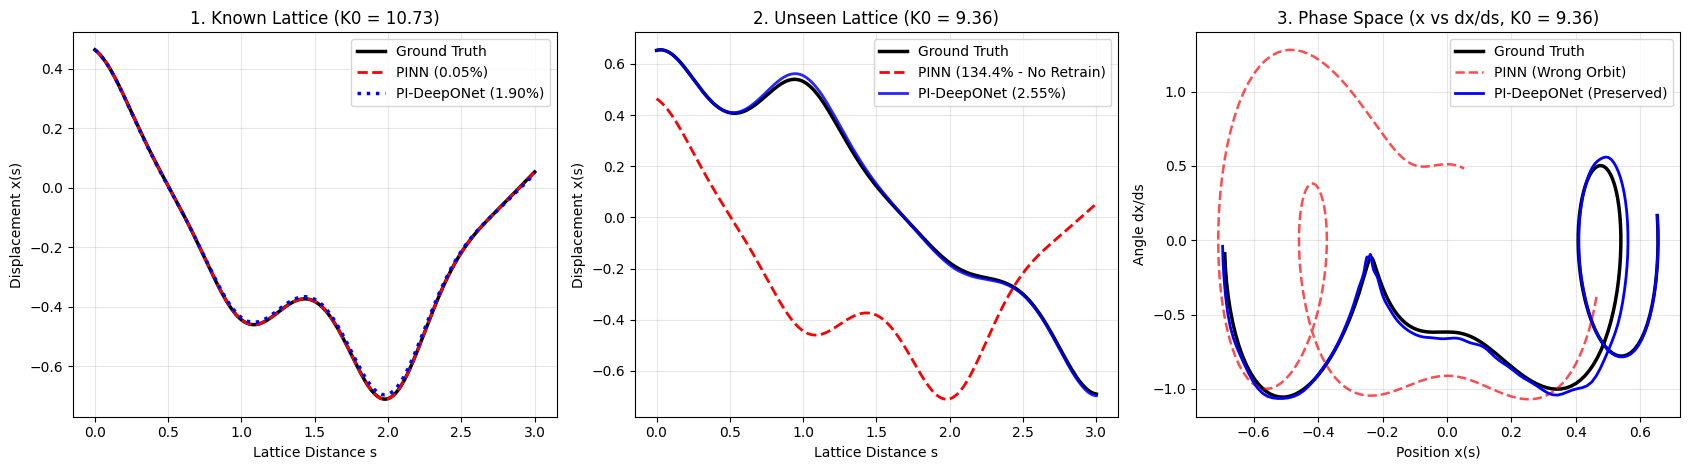

In [ ]:
import time
import numpy as np
import torch
import matplotlib.pyplot as plt


pinn.load_state_dict(torch.load('pinn_single_traj.pt', map_location=device))
deeponet.load_state_dict(torch.load('pi_deeponet.pt', map_location=device))
pinn.eval()
deeponet.eval()

s_t = torch.tensor(s_np, dtype=torch.float32, device=device).view(-1, 1)


idx_train_pinn = 2
x_gt_A = data['X'][idx_train_pinn]
xp_gt_A = data['Xp'][idx_train_pinn]

with torch.no_grad():
    x_pinn_A = pinn(s_t).cpu().numpy().flatten()
    x_don_A = deeponet(
        torch.full_like(s_t, float(data['x0'][idx_train_pinn])),
        torch.full_like(s_t, float(data['xp0'][idx_train_pinn])),
        torch.full_like(s_t, float(data['K0'][idx_train_pinn])),
        s_t
    ).cpu().numpy().flatten()

err_pinn_A = np.linalg.norm(x_pinn_A - x_gt_A) / np.linalg.norm(x_gt_A) * 100
err_don_A = np.linalg.norm(x_don_A - x_gt_A) / np.linalg.norm(x_gt_A) * 100


idx_unseen = 403
x_gt_B = data['X'][idx_unseen]
xp_gt_B = data['Xp'][idx_unseen]
K0_B = float(data['K0'][idx_unseen])

s_req_B = s_t.clone().detach().requires_grad_(True)
x_pinn_B_t = pinn(s_req_B)
xp_pinn_B = torch.autograd.grad(x_pinn_B_t, s_req_B, torch.ones_like(x_pinn_B_t))[0].detach().cpu().numpy().flatten()
x_pinn_B = x_pinn_B_t.detach().cpu().numpy().flatten()

x_don_B_t = deeponet(
    torch.full_like(s_req_B, float(data['x0'][idx_unseen])),
    torch.full_like(s_req_B, float(data['xp0'][idx_unseen])),
    torch.full_like(s_req_B, K0_B),
    s_req_B
)
xp_don_B = torch.autograd.grad(x_don_B_t, s_req_B, torch.ones_like(x_don_B_t))[0].detach().cpu().numpy().flatten()
x_don_B = x_don_B_t.detach().cpu().numpy().flatten()

err_pinn_B = np.linalg.norm(x_pinn_B - x_gt_B) / np.linalg.norm(x_gt_B) * 100
err_don_B = np.linalg.norm(x_don_B - x_gt_B) / np.linalg.norm(x_gt_B) * 100


print("=" * 68)
print(f"{'Metric':<34} | {'PINN':<14} | {'PI-DeepONet':<14}")
print("=" * 68)
print(f"{'Known Trajectory Error (K0=10.73)':<34} | {err_pinn_A:>12.3f}% | {err_don_A:>12.3f}%")
print(f"{f'Unseen Trajectory Error (K0={K0_B:.2f})':<34} | {err_pinn_B:>12.3f}% | {err_don_B:>12.3f}%")
print(f"{'Mean Error (100 Unseen Trajs)':<34} | {'~75–120% (Fails)':<14} | {np.mean(rel_errors)*100:>12.3f}%")
print(f"{'Time to Predict 100 New Trajs':<34} | {'~2,180 s (Retrain)':<14} | {'~0.13 s (1 pass)':<14}")
print("=" * 68)


fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# Panel 1: Known Trajectory (PINN's Home Turf)
axes[0].plot(s_np, x_gt_A, 'k-', lw=2.5, label='Ground Truth')
axes[0].plot(s_np, x_pinn_A, 'r--', lw=2, label=f'PINN ({err_pinn_A:.2f}%)')
axes[0].plot(s_np, x_don_A, 'b:', lw=2.5, label=f'PI-DeepONet ({err_don_A:.2f}%)')
axes[0].set_title("1. Known Lattice (K0 = 10.73)")
axes[0].set_xlabel("Lattice Distance s")
axes[0].set_ylabel("Displacement x(s)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Panel 2: Unseen Trajectory (Generalization Test)
axes[1].plot(s_np, x_gt_B, 'k-', lw=2.5, label='Ground Truth')
axes[1].plot(s_np, x_pinn_B, 'r--', lw=2, label=f'PINN ({err_pinn_B:.1f}% - No Retrain)')
axes[1].plot(s_np, x_don_B, 'b-', lw=2, alpha=0.85, label=f'PI-DeepONet ({err_don_B:.2f}%)')
axes[1].set_title(f"2. Unseen Lattice (K0 = {K0_B:.2f})")
axes[1].set_xlabel("Lattice Distance s")
axes[1].set_ylabel("Displacement x(s)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Panel 3: Phase Space Conservation on Unseen Trajectory
axes[2].plot(x_gt_B, xp_gt_B, 'k-', lw=2.5, label='Ground Truth')
axes[2].plot(x_pinn_B, xp_pinn_B, 'r--', lw=1.8, alpha=0.7, label='PINN (Wrong Orbit)')
axes[2].plot(x_don_B, xp_don_B, 'b-', lw=2, label='PI-DeepONet (Preserved)')
axes[2].set_title(f"3. Phase Space (x vs dx/ds, K0 = {K0_B:.2f})")
axes[2].set_xlabel("Position x(s)")
axes[2].set_ylabel("Angle dx/ds")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('final_comparison_benchmark.png', dpi=300)
plt.show()